# Intro

<span style="color:green">
In this miniproject, you will compare the standard perceptron rule with the normalized perceptron rule.

standard perceptron:
W_new = W_old + e*p.T , b_new = b_old + e

normalized perceptron:
W_new = W_old + e*p.T/||p|| , b_new = b_old + e/||p||
</span>

DISCLAIMER: generative ai use is highlighted where applicable (specifcally one function in section 5). 

A changelog and supporting files can be found on my self hosted Forgejo instance located [here](https://bazzite.tail24e006.ts.net/forgejo/brouser/ECEN-MAE-5733)

In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
%matplotlib inline

# 1. Perceptron And Learning Rules

<span style="color:green">
Write a python method to implement the perceptron network and both learning rules. Write the method using matrix operations (as in Equations (4.38) and (4.39))
</span>

In [3]:
#define activation functions

def hardlims(n):
    '''symmetrical hard limit function for input vector n'''
    return np.where(n < 0, -1, 1)
    
def hardlim(n):
    ''' hard limit function for input vector n'''
    return np.where(n < 0, 0, 1)

def poslin(n): #we don't actually need this for single layer perceptron but can become useful later
    '''positive linear function for input vector n'''
    return np.where(n < 0, 0, n)

In [4]:
#define base perceptron class
class Perceptron():
    '''single layer perceptron class. From textbook inputs p should have n_inputs=R and the output of the model should have n_outputs=S'''
    def __init__(self, weight_shape:list|None=None, weights:np.ndarray=None, bias:np.ndarray=None, activation=hardlims):
        self.activation=activation
        if weights is None:
            if weight_shape is None: #weight shape should be [S,R]
                raise ValueError('you must provide a weight or input/output shape')
            weights=np.random.rand(*weight_shape)
        self.W=np.asarray(weights).astype(float) #ensure float type

        #set shape vars and ensure 2d
        if self.W.ndim==1: self.W=self.W.reshape(1,-1)
        self.S=self.W.shape[0]
        self.R=self.W.shape[1]

        #ensure b is floats with 2 dimensions
        if bias is None:
            bias=np.random.rand(*[1,self.S])
        self.b=np.asarray(bias).astype(float)
        if self.b.ndim==1: self.b=self.b.reshape(1,self.S)
        

    def _shape_input(self, p:np.ndarray)->np.ndarray:
        p=np.asarray(p) 
        if p.ndim == 1:
            p = p.reshape(1, -1)
        elif p.ndim != 2:
            raise ValueError(f"Input must be 1D or 2D array, got {p.ndim}D.")
        assert p.shape[1]==self.R , f'input shape {p.shape} doesn\'t match expected length {self.R}'
        return p
    
    def forward(self, p:np.ndarray)->np.ndarray:
        '''compute forward pass through the perception for input vector p'''
        #safety check
        p=self._shape_input(p)
        #compute output
        n=p@self.W.T
        n=n+self.b
        return self.activation(n).reshape(-1,self.S)

In [5]:
# basic sanity check, see ch 3.7
W=[0,1,0]
b=[0]

network=Perceptron(weights=W,bias=b)
output_map={-1:'orange', 1:'apple'}

orange=[1, -1, -1]
apple=[1, 1, -1]
mystery_apple=[0.7, 1e6, -2] #should match apple since decision boundary only relies on second element
mystery_orange=[1000, -1e6, 50]
inputs=[orange,apple,mystery_apple, mystery_orange]

output=network.forward(inputs)
for o in output:
    print(output_map[o[0]])

orange
apple
apple
orange


In [6]:
#what about 2 neurons?
W=[[0,1,0],[0,1,0]]
b=[0,0]
network=Perceptron(weights=W,bias=b)
output=network.forward(inputs)
print(output) #since weights are the same for both neurons each output feature is the same and matches the correct target

[[-1 -1]
 [ 1  1]
 [ 1  1]
 [-1 -1]]


In [7]:
#extend perceptron to have learning methods
class LearningPerceptron(Perceptron):

    def _update(self,p:np.ndarray,e:np.ndarray):#define this here to help with syntax highlighting
        raise NotImplementedError('perceptron hasn\'t been initilized yet')
    
    def __init__(self, weight_shape=None, weights = None, bias = None, activation=hardlims, learning='standard'):
        super().__init__( weight_shape, weights, bias, activation)
        learning_map={'standard':self._standard_learning, 'normalized':self._normalized_learning}
        if learning not in list(learning_map.keys()): raise ValueError(r'learning function must be "standard" or "normalized"')
        self.update=learning_map[learning]

    def _standard_learning(self,p:np.ndarray, e:np.ndarray):
        return (e.T@p, e) # (weight, bias)
        
    def _normalized_learning(self,p:np.ndarray, e:np.ndarray):
        return e.T@p/np.linalg.norm(p), (e/np.linalg.norm(p))

    def learn(self,p:np.ndarray, t:np.ndarray)->list: 
        #ensure proper shapes 
        t=np.asarray(t).reshape(-1,self.S)
        error=[]
        for _p, _t in zip(p,t): #loop through and apply updates instead of using whole batch at once
            #forward pass and error
            _p=self._shape_input(_p)
            a=self.forward(_p)
            e = _t - a 
            error.append(e)

            #update weights/bias
            w_update, b_update=self.update(_p,e)
            self.W+=w_update
            self.b+=b_update
        return error

In [8]:
learning='normalized'
W=[0,1,0]
b=[0]
network=LearningPerceptron(weights=W,bias=b,learning=learning) #use params defined in previous sanity check
inputs=[orange,apple,mystery_apple] #we'll use the same inputs as our sanity check
targets=[-1,1, -1] #add in a misclass

#check if weights update
network.learn(inputs,targets)
print(network.W)

[[-1.4e-06 -1.0e+00  4.0e-06]]


In [9]:
#2 neuron case
learning='normalized'
W=[[0,1,0],[0,1,0]]
b=[0,0]
network=LearningPerceptron(weights=W,bias=b,learning=learning) #use params defined in previous sanity check
inputs=[orange,apple,mystery_apple] #we'll use the same inputs as our sanity check
targets=[[-1,-1],[1,1], [-1,-1]] #add in a misclass

#check if weights update
network.learn(inputs,targets)
print(network.W)

[[-1.4e-06 -1.0e+00  4.0e-06]
 [-1.4e-06 -1.0e+00  4.0e-06]]


# 2. Pattern Recognition

<span style="color:green">
Make up one or more pattern recognition problems that can be solved with a perceptron network. Have the input vectors be two dimensional, and separate these vectors into four different classes. Use at least 12 different input vectors in the training set.

The scaling of your test problem matters. Design at least one problem in which the input
vectors have widely differing magnitudes. 
</span>

For this miniproject I wanted to experiment with linear transforms. This includes shifts in bias and application of rotation matracies on our input vectors. To keep things simple for visulization I only used two features per input vector, but the fundemental concepts should hold for any number of input features. Additionally I utalize 20 samples per experimental case to reduce the ammount of computational power required to converge the perceptrons. You can up the number of samples if you want, but be advised that this will greatly increase the time to converge.

In [10]:
#setup common vars for training data
n_samples=20
input_size=[n_samples,2]
label_map={(-1,-1):'blue',
           (-1,1):'green',
           (1,-1):'yellow',
           (1,1):'red'}

## basic problem

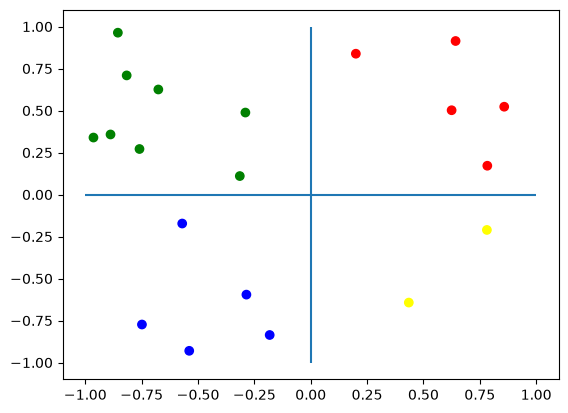

In [11]:
#basic 2d example (normalized scale)

#create input vector and labels
np.random.seed(8675309)
basic_inputs=np.random.uniform(-1,1,input_size)
basic_labels=hardlims(basic_inputs)
basic_colors=[label_map[tuple(l)] for l in basic_labels]

plt.figure()
plt.scatter(basic_inputs[:,0], basic_inputs[:,1],c=basic_colors)
plt.vlines([0],-1,1)
plt.hlines([0],-1,1)
plt.show()

In [12]:
#simple perceptron without learning
W=[[1,0],[0,1]]
b=[0,0]
network=Perceptron(weights=W,bias=b)
outputs=network.forward(basic_inputs)

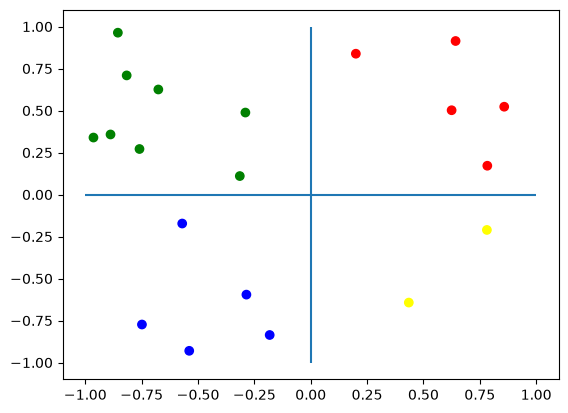

In [13]:
#plot inputs colored by outputs
colors=[label_map[tuple(o)] for o in outputs]
plt.figure()
plt.scatter(basic_inputs[:,0], basic_inputs[:,1],c=colors)
plt.vlines([0],-1,1)
plt.hlines([0],-1,1)
plt.show()

In [14]:
error=basic_labels-outputs
print(np.mean(error)) #perfect classification

0.0


## rotated problem

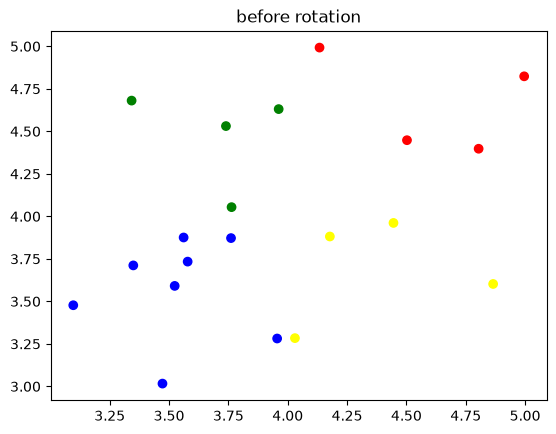

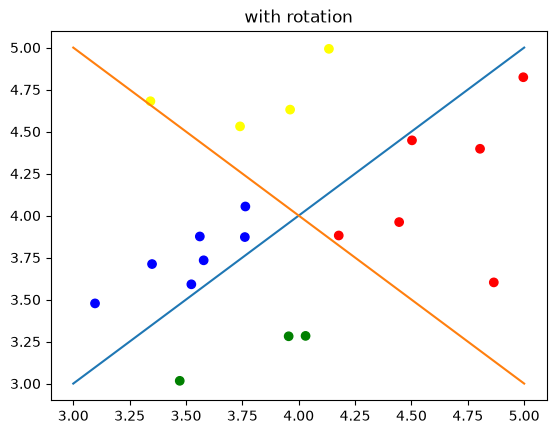

In [15]:
#2d example with rotation + shift (normalized scale)
# note this isn't a *true* rotation, rather a linear transformation. which is why class labels are rotated and flipped

#create input vector and labels
bias=4
np.random.seed(int.from_bytes('seed'.encode(),byteorder='big'))
rotated_inputs=np.random.uniform(-1,1,input_size)+bias #add bias after rng
prerotated_labels=hardlims(rotated_inputs-bias)
rotated_colors=[label_map[tuple(l)] for l in prerotated_labels] #use colormap defined previously
plt.figure()
plt.scatter(rotated_inputs[:,0], rotated_inputs[:,1],c=rotated_colors)
plt.title('before rotation')
plt.show()

rotation=np.array([[1,1],[1,-1]])
rotated_labels=hardlims((rotated_inputs-bias)@rotation) #uses transform to define labels
rotated_colors=[label_map[tuple(l)] for l in rotated_labels] #use colormap defined previously

plt.figure()
plt.scatter(rotated_inputs[:,0], rotated_inputs[:,1],c=rotated_colors)
plt.plot([-1+bias,1+bias],[-1+bias,1+bias])
plt.plot([-1+bias,1+bias],[1+bias,-1+bias])
plt.title('with rotation')
plt.show()

## rotation + scale

Note: I orginially applied a log transform to scale the data but this caused issues with negative values. Thus a constant upscale is applied instead

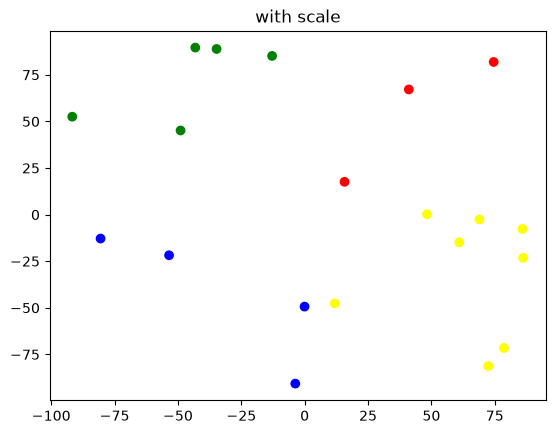

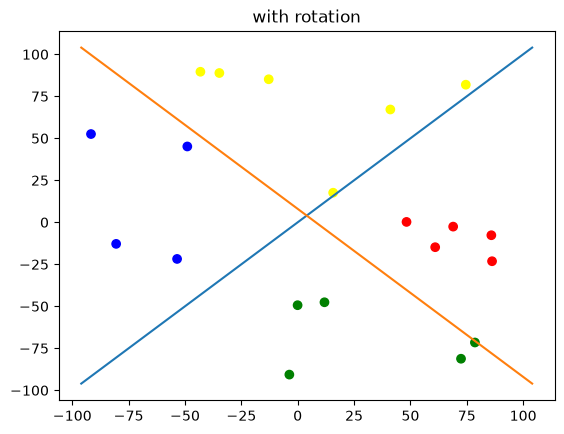

In [16]:
#2d example with rotation + shift and scaling

#create input vector and labels
bias=4
scale=100
np.random.seed(int.from_bytes('nnet'.encode(),byteorder='big'))
scaled_inputs=np.random.uniform(-1,1,input_size)*scale+bias #add scale+transform before bias
prerotated_labels=hardlims(scaled_inputs-bias)
scaled_colors=[label_map[tuple(l)] for l in prerotated_labels] #use colormap defined previously
plt.figure()
plt.scatter(scaled_inputs[:,0], scaled_inputs[:,1],c=scaled_colors)
plt.title('with scale')
plt.show()

rotation=np.array([[1,1],[1,-1]])
scaled_labels=hardlims((scaled_inputs-bias)@rotation) #uses transform to define labels
scaled_colors=[label_map[tuple(l)] for l in scaled_labels] #use colormap defined previously

plt.figure()
plt.scatter(scaled_inputs[:,0], scaled_inputs[:,1],c=scaled_colors)
plt.plot([-1*scale+bias,1*scale+bias],[-1*scale+bias,1*scale+bias])
plt.plot([-1*scale+bias,1*scale+bias],[1*scale+bias,-1*scale+bias])
plt.title('with rotation')
plt.show()

# 3. Prediction

<span style="color:green">
Write down your prediction before you run the experiment. The notebook must contain a
section titled Prediction, placed before any results, stating which problem you expect to show the
larger difference between the two rules and why. You will not be graded on whether the prediction
turns out to be right. You will be graded on the reasoning behind it, and on your explanation of any
respect in which it turned out to be wrong
</span>

This experiment will be conducted using a 2x3 design by manipulating the complexity of the learning rule (standard vs normalized) and the input vector complexity (normalized, rotated+bias, rotated+bias+scaled). Thus there will  be three predicted comparisons across perceptron learning rules:

1. (normalized inputs): Both learning rules should converge in a timely manner since the input vectors are linearly separable and ||p|| is close to 1.
2. (rotated+bias): I expect the normalized rule to converge faster since ||p|| is greater than 1 due to the added bias term. The rotation shouldn't affect convergence of the standard model here compared to the standard model trained on normalized inputs  
3. (rotation+bias+scale): Here I expect the normalized learning rule to converge much faster than the standard as ||p|| is correlated to the class. Additionally we expect the standard rule here to converge slower compared to cases 1 and 2. 

# 4. Training

<span style="color:green">
Train perceptron networks to solve your problems with both rules, and compare average convergence rates. To find average convergence rates, train the network at least 100 different times with each rule, with different initial random weights each time 

use the numpy.random.rand method to generate random weights. Find the average number of iterations to reach convergence from the 100 trials. Investigate different properties of the problem and the network that might affect the comparison
</span>

I had to redo the training loop for the learning perceptron because convergence usually takes multiple passes through training data

In [17]:
#extend perceptron to have learning methods
class LearningPerceptron(Perceptron):

    def _update(self,p:np.ndarray,e:np.ndarray):#define this here to help with syntax highlighting
        raise NotImplementedError('perceptron hasn\'t been initilized yet')
    
    def __init__(self, weight_shape=None, weights = None, bias = None, activation=hardlims, learning='standard'):
        super().__init__( weight_shape, weights, bias, activation)
        learning_map={'standard':self._standard_learning, 'normalized':self._normalized_learning}
        if learning not in list(learning_map.keys()): raise ValueError(r'learning function must be "standard" or "normalized"')
        self.update=learning_map[learning]

    def _standard_learning(self,p:np.ndarray, e:np.ndarray):
        return (e.T@p, e) # (weight, bias)
        
    def _normalized_learning(self,p:np.ndarray, e:np.ndarray):
        return e.T@p/np.linalg.norm(p), (e/np.linalg.norm(p))

    def learn(self,p:np.ndarray, t:np.ndarray, max_epoch=100)->list: 
        #ensure proper shapes 
        t=np.asarray(t).reshape(-1,self.S)
        error=[]
        n_epoch=0
        n_iter=0
        while True:
            for _p, _t in zip(p,t): #loop through and apply updates instead of using whole batch at once
                #forward pass and error
                _p=self._shape_input(_p)
                a=self.forward(_p)
                e = _t - a 
                error.append(e)

                #update weights/bias
                w_update, b_update=self.update(_p,e)
                self.W+=w_update
                self.b+=b_update
                n_iter+=1
            n_epoch+=1
            if np.all(np.asarray(error) == 0):break #all error=0 -> perfect classification ->break out of training loop
            error=[] #reset for next epoch
            if n_epoch>max_epoch: 
                print('warning, max epoch reached when training')
                break
        return n_iter

In [18]:
def train_network(n_outputs, n_features,inputs,targets,learning:str='standard',n_iter:int=100, max_epoch=1000):
    weight_shape=[n_outputs,n_features]
    itterations=[]
    for i in range(n_iter):
        network=LearningPerceptron(weight_shape=weight_shape,learning=learning) #init new net every time
        itterations.append(network.learn(inputs,targets,max_epoch=max_epoch))   
    plt.figure()
    plt.plot(itterations)
    plt.title(learning)
    plt.show()
    return {'network':network,'itter':itterations}

## basic

### single network example

In [19]:
network=LearningPerceptron(weight_shape=[2,2])
n_epoch=network.learn(basic_inputs,basic_labels)
print(f'converged in {n_epoch} epochs')
out=network.forward(basic_inputs)

converged in 160 epochs


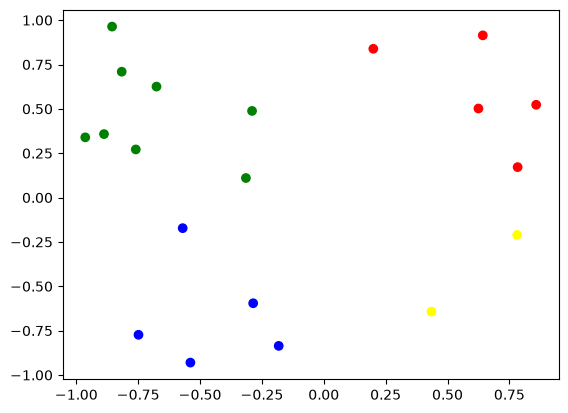

In [20]:
#true class
plt.figure()
plt.scatter(basic_inputs[:,0],basic_inputs[:,1],color=basic_colors)
plt.show()

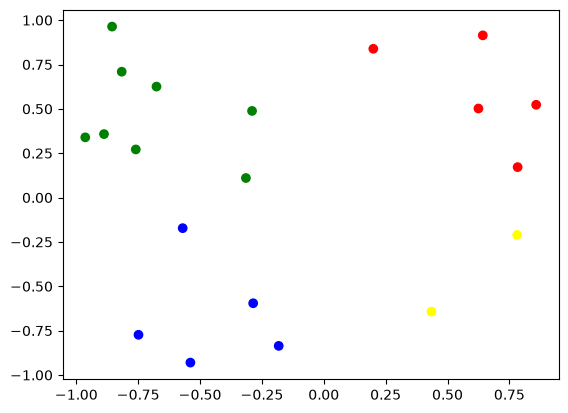

In [21]:
# predicted class
color=[label_map[tuple(l)] for l in out]
plt.figure()
plt.scatter(basic_inputs[:,0],basic_inputs[:,1],color=color)
plt.show()

In [22]:
error=basic_labels-out
print(np.mean(np.abs(error),axis=0)) #0,0 = perfect classification

[0. 0.]


In [23]:
network.W

array([[3.24522654, 1.26703571],
       [1.54551239, 8.53382299]])

### experiment with 100 network weights

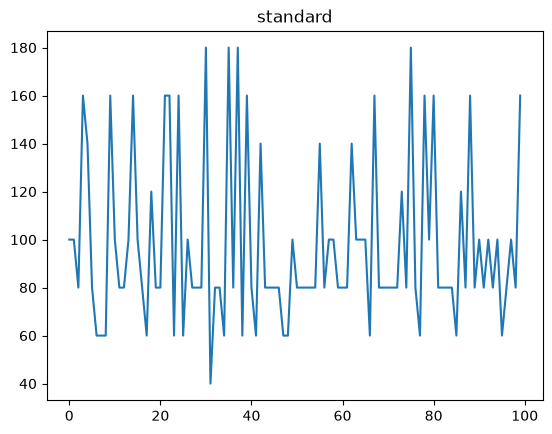

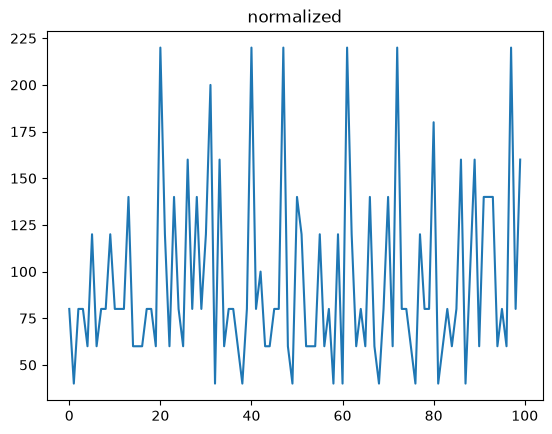

case 1 standard itterations ~ 97.2
case 1 normalized itterations ~ 94.6


In [24]:
case1_standard=train_network(2,2,basic_inputs,basic_labels,n_iter=100,learning='standard')
case1_normalized=train_network(2,2,basic_inputs,basic_labels,n_iter=100,learning='normalized')

print(f'case 1 standard itterations ~ {np.mean(case1_standard['itter'])}')
print(f'case 1 normalized itterations ~ {np.mean(case1_normalized['itter'])}')

Our prediciton holds, both networks converge quickly. However the normalized learning rule consistantly outperforms the standard.

## rotation

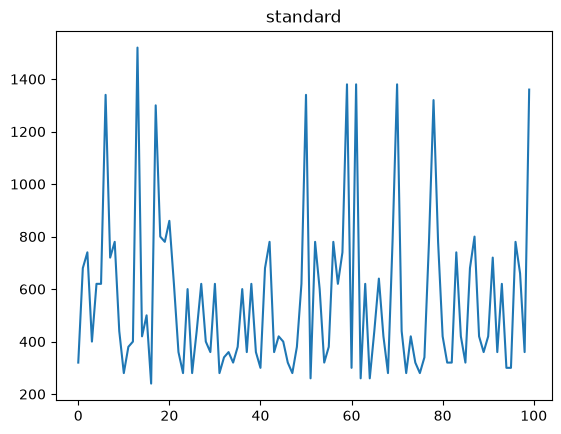

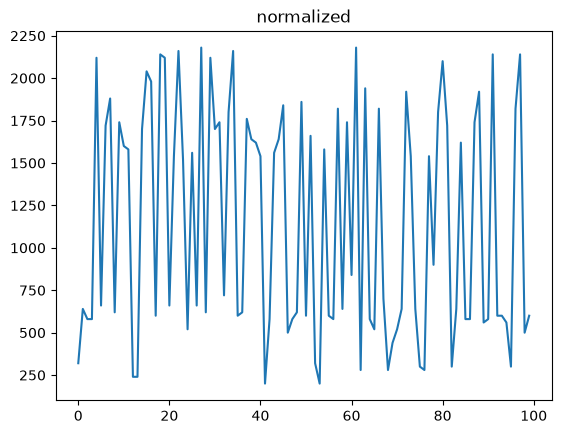

case 2 standard itterations ~ 564.8
case 2 normalized itterations ~ 1149.2


In [25]:
case2_standard=train_network(2,2,rotated_inputs,rotated_labels,n_iter=100,learning='standard')
case2_normalized=train_network(2,2,rotated_inputs,rotated_labels,n_iter=100,learning='normalized')

print(f'case 2 standard itterations ~ {np.mean(case2_standard['itter'])}')
print(f'case 2 normalized itterations ~ {np.mean(case2_normalized['itter'])}')

my prediction fails for case 2. this is likely due to the added bias shifting the center of our data away from 0. This can be verified by subtracting the bias out of our data but leaving the linear transformation. Shifting the norm ||p|| higher causes smaller changes to the weights and biases thus increasing convergence time

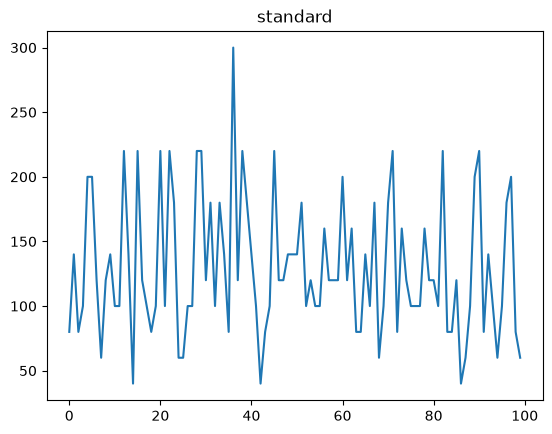

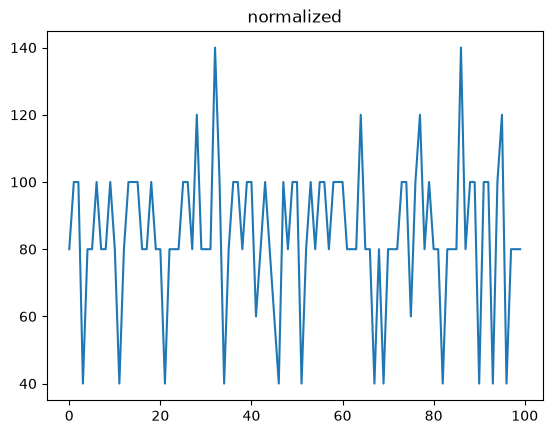

case 2 standard itterations ~ 129.2
case 2 normalized itterations ~ 84.2


In [26]:
case2_standard_nobias=train_network(2,2,rotated_inputs-bias,rotated_labels,n_iter=100,learning='standard')
case2_normalized_nobias=train_network(2,2,rotated_inputs-bias,rotated_labels,n_iter=100,learning='normalized')

print(f'case 2 standard itterations ~ {np.mean(case2_standard_nobias['itter'])}')
print(f'case 2 normalized itterations ~ {np.mean(case2_normalized_nobias['itter'])}')

## rotation + scale

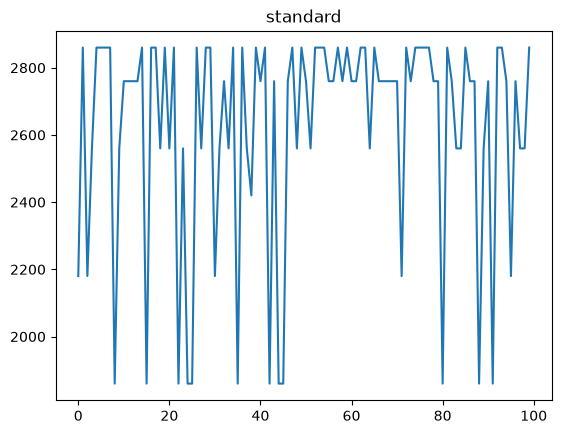

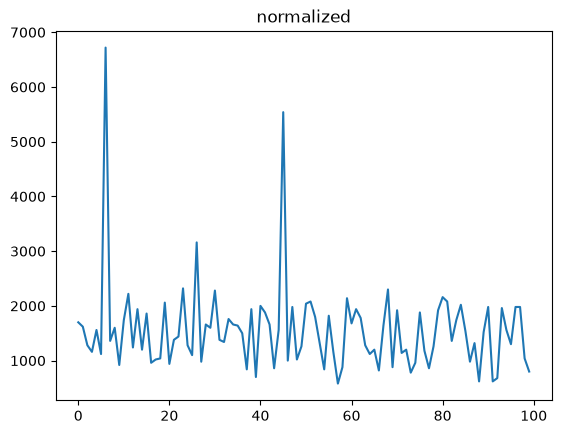

case 3 standard itterations ~ 2622.6
case 3 normalized itterations ~ 1556.2


In [27]:
case3_standard=train_network(2,2,scaled_inputs,scaled_labels,n_iter=100,learning='standard')
case3_normalized=train_network(2,2,scaled_inputs,scaled_labels,n_iter=100,learning='normalized')

print(f'case 3 standard itterations ~ {np.mean(case3_standard['itter'])}')
print(f'case 3 normalized itterations ~ {np.mean(case3_normalized['itter'])}')

My prediction for case 3 is correct. Even with the added bias and transform, since input vectors vary widely in scale, adding the normalization to our learning rule causes less chaotic updates to our network weights thus reducing the overall time to converge

Note: it appears we can actually see the maximum itterations required in our standard learning rule plot. We should see if our calculated convergence ceiling matches this

In [28]:
np.max(case3_standard['itter'])

np.int64(2860)

# 5. Discussion

<span style="color:green">
Finally, connect what you observe to the convergence proof in the text. The bound on the
number of iterations needed for convergence, which is given in Eq. (4.76), involves Π = max{‖z‖2},
the maximum squared length of the augmented input vectors, and δ , which measures how close the
solution decision boundary comes to the input patterns. Compute Π and δ for your test problems,
using one of your trained solutions as x∗, and discuss how these quantities change when the input
vectors are normalized. Does the bound help explain the behavior you measured? Where does it fail
to explain what you see?
</span>

In [29]:
def compute_upper_bound(network, inputs):
    x_optimal = np.concatenate([network.W, network.b.T], axis=1)
    z = np.concatenate([inputs, np.ones((n_samples, 1))], axis=1)
    PI = np.max(np.linalg.norm(z, axis=1)**2)
    delta = np.min(np.abs(z @ x_optimal.T))
    k = (PI * np.linalg.norm(x_optimal)**2) / delta**2
    return {'k':k, 'pi':PI, 'delta':delta, 'x*':x_optimal}

In [30]:
#note: I used a self hosted qwen model to write some of this function (specifically the isclose lines)
def plot_boundry(network:Perceptron, inputs:np.ndarray, colors:list=None, title=None):
    x0=inputs[:,0].min()
    x1=inputs[:,0].max()
    y0=inputs[:,1].min()
    y1=inputs[:,1].max()
    x = np.linspace(x0, x1, 500)

    plt.figure()
    for i in range(network.S):
        w1, w2 = network.W[i]
        b = network.b[0, i]

        if np.isclose(w2, 0):
            # Vertical boundary: x = -b/w1
            if not np.isclose(w1, 0):
                x_boundary = -b / w1
                plt.axvline(
                    x_boundary,
                    label=f"Boundary {i+1}"
                )
        else:
            y = -(w1 * x + b) / w2
            plt.plot(
                x, y,
                label= f"Boundary {i+1}"
            )

    plt.scatter(inputs[:,0],inputs[:,1],color=colors)
    plt.xlim([x0,x1])
    plt.ylim([y0,y1])
    if title: plt.title(title)
    plt.show()

### ai transcript

can you create a function that plots the decision boundries given the weights and biases? #define base perceptron class
class Perceptron():
    '''single layer perceptron class. From textbook inputs p should have n_inputs=R and the output of the model should have n_outputs=S'''
    def __init__(self, weight_shape:list|None=None, weights:np.ndarray=None, bias:np.ndarray=None, activation=hardlims):
        self.activation=activation
        if weights is None:
            if weight_shape is None: #weight shape should be [S,R]
                raise ValueError('you must provide a weight or input/output shape')
            weights=np.random.rand(*weight_shape)
        self.W=np.asarray(weights).astype(float) #ensure float type

        #set shape vars and ensure 2d
        if self.W.ndim==1: self.W=self.W.reshape(1,-1)
        self.S=self.W.shape[0]
        self.R=self.W.shape[1]

        #ensure b is floats with 2 dimensions
        if bias is None:
            bias=np.random.rand(*[1,self.S])
        self.b=np.asarray(bias).astype(float)
        if self.b.ndim==1: self.b=self.b.reshape(1,self.S)
        

    def _shape_input(self, p:np.ndarray)->np.ndarray:
        p=np.asarray(p) 
        if p.ndim == 1:
            p = p.reshape(1, -1)
        elif p.ndim != 2:
            raise ValueError(f"Input must be 1D or 2D array, got {p.ndim}D.")
        assert p.shape[1]==self.R , f'input shape {p.shape} doesn\'t match expected length {self.R}'
        return p
    
    def forward(self, p:np.ndarray)->np.ndarray:
        '''compute forward pass through the perception for input vector p'''
        #safety check
        p=self._shape_input(p)
        #compute output
        n=p@self.W.T
        n=n+self.b
        return self.activation(n).reshape(-1,self.S)

import numpy as np
import matplotlib.pyplot as plt

def plot_decision_boundaries(perceptron, xlim=(-10, 10), ylim=(-10, 10),
                             ax=None, labels=None):
    """
    Plot decision boundaries for a 2-input Perceptron.

    Each output neuron defines:
        w1*x + w2*y + b = 0

    Parameters
    ----------
    perceptron : Perceptron
        Perceptron whose weights and biases should be plotted.
    xlim, ylim : tuple
        Plotting limits for x and y.
    ax : matplotlib.axes.Axes, optional
        Existing axes to plot on.
    labels : list, optional
        Labels for each decision boundary.
    """

    if perceptron.R != 2:
        raise ValueError(
            f"Decision boundary plotting requires exactly 2 inputs, "
            f"but this perceptron has R={perceptron.R}."
        )

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    x = np.linspace(xlim[0], xlim[1], 500)

    for i in range(perceptron.S):
        w1, w2 = perceptron.W[i]
        b = perceptron.b[0, i]

        # w1*x + w2*y + b = 0
        # y = -(w1*x + b) / w2
        if np.isclose(w2, 0):
            # Vertical boundary: x = -b/w1
            if not np.isclose(w1, 0):
                x_boundary = -b / w1
                ax.axvline(
                    x_boundary,
                    label=labels[i] if labels else f"Boundary {i+1}"
                )
        else:
            y = -(w1 * x + b) / w2
            ax.plot(
                x, y,
                label=labels[i] if labels else f"Boundary {i+1}"
            )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title("Perceptron Decision Boundaries")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=0.5)
    ax.grid(True, alpha=0.3)
    ax.legend()

    return ax


Explination of my edits:
This function is verbose and I also wanted my input vectors plotted as well. These edits were made by myself and verrified without extra help from generative models 

## case 1

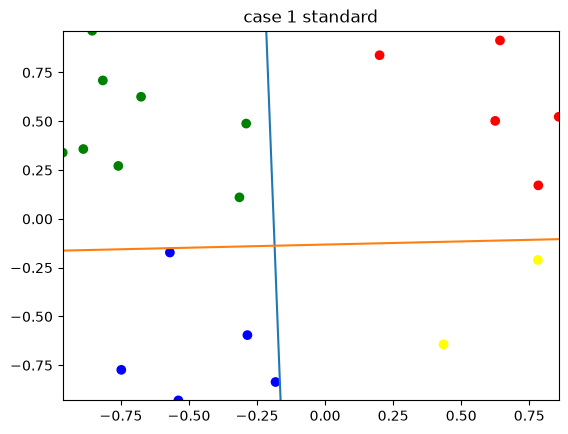

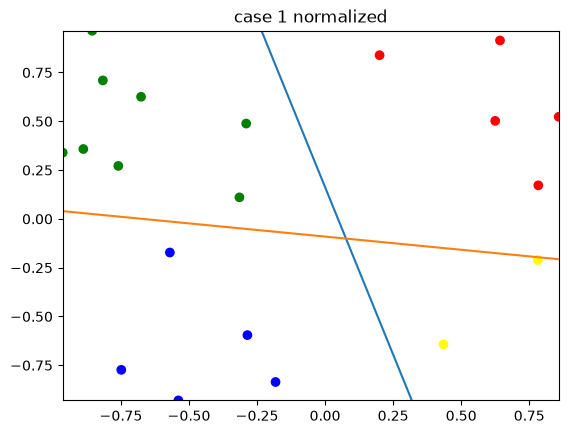

In [31]:
plot_boundry(case1_standard['network'],basic_inputs, basic_colors, title='case 1 standard')
plot_boundry(case1_normalized['network'],basic_inputs, basic_colors, title='case 1 normalized')

In [44]:
k_1_standard=compute_upper_bound(case1_standard['network'],basic_inputs)
k_1_normalized=compute_upper_bound(case1_normalized['network'],basic_inputs)
print('case 1 standard:', k_1_standard ['pi'] ,k_1_standard ['delta'])
print('weights', k_1_standard['x*'])
print('case 1 normalized:',k_1_normalized ['pi'] ,k_1_normalized ['delta'])
print('weights', k_1_normalized['x*'])

case 1 standard: 2.6604227745906823 0.06343053952568212
weights [[ 3.96588694  0.11028695  0.75052432]
 [-0.21620987  6.71720617  0.88339819]]
case 1 normalized: 2.6604227745906823 0.14569043652725
weights [[ 6.33063607  1.84534481 -0.30028721]
 [ 1.39507013 10.32021644  0.93532186]]


For case 1 we see that PI is independant of the network weights and is constant between the two learning rules. Thus values of delta are the most important.

For delta < 1 the maximum number of itterations will increase. Thus since the normalized delta is larger than the standard delta, we expect the normalized learning rule to converge faster

In [33]:
print(k_1_standard['k']>=k_1_normalized['k'])

True


## case 2

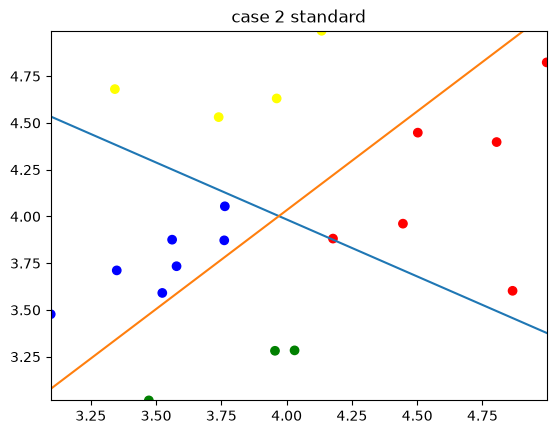

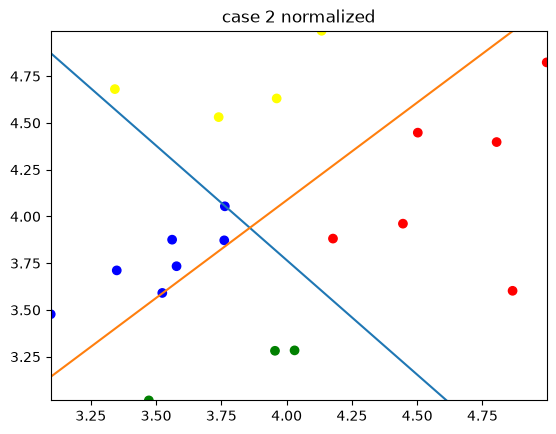

In [40]:
plot_boundry(case2_standard['network'],rotated_inputs, rotated_colors, title='case 2 standard')
plot_boundry(case2_normalized['network'],rotated_inputs, rotated_colors, title='case 2 normalized')

In [45]:

k_2_standard=compute_upper_bound(case2_standard['network'],rotated_inputs)
k_2_normalized=compute_upper_bound(case2_normalized['network'],rotated_inputs)
print('case 2 standard:', k_2_standard ['pi'] ,k_2_standard ['delta'])
print('weights', k_2_standard['x*'])
print('case 2 normalized:',k_2_normalized ['pi'] ,k_2_normalized ['delta'])
print('weights', k_2_normalized['x*'])

case 2 standard: 49.22783027559731 0.1141323557008036
weights [[  11.75918687   19.30307595 -123.93607143]
 [  41.61599997  -39.37069067   -7.67304123]]
case 2 normalized: 49.22783027559731 0.002596959246464081
weights [[  1.44533649   1.18002134 -10.22590436]
 [  7.71070753  -7.3806481   -0.68208221]]


Case 2 highlights how input vector magnitude can cause perceptron learning to vary regardless of rule. This is evident comparing k between case 1 and case 2 as case 2 included a bias to the input vectors increasing delta regardless of learning rule. Here we also see that delta for the normalized rule is smaller than the standard, thus increasing the time to converge for the normalized rule

In [36]:
print(k_2_standard['k']<=k_2_normalized['k'])

True


## case 3

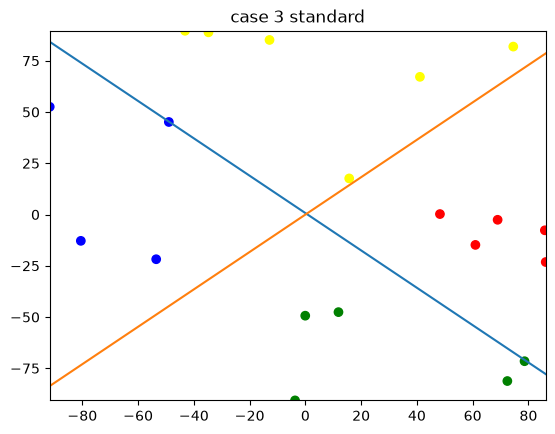

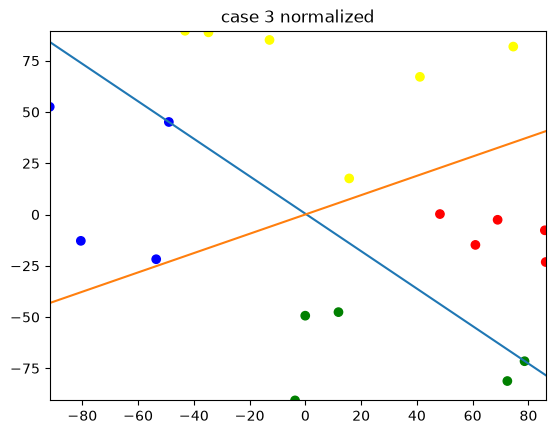

In [37]:
plot_boundry(case3_standard['network'],scaled_inputs, scaled_colors, title='case 3 standard')
plot_boundry(case3_normalized['network'],scaled_inputs, scaled_colors, title='case 3 normalized')

In [ ]:

k_3_standard=compute_upper_bound(case3_standard['network'],scaled_inputs)
k_3_normalized=compute_upper_bound(case3_normalized['network'],scaled_inputs)
print('case 3 standard:', k_3_standard ['pi'] , _3_standard ['delta'])
print('weights', k_3_standard['x*'])
print('case 3 normalized:',k_3_normalized ['pi'] ,k_3_normalized ['delta'])
print('weights', k_3_normalized['x*'])

case 3 standard: 12270.206335840348 124.43692259341998
weights [[ 608.37018421  667.71341429 -479.78603621]
 [ 132.42726734 -145.1986296    -3.98626059]]
case 3 normalized: 12270.206335840348 0.030830041582720957
weights [[ 3.97959114  4.35494969 -1.77614642]
 [ 1.22642821 -2.60309366  0.09507814]]


Case 3 indicates that a large variation in input vector magnitude will cause drasitcally different behavior between learning rules. The only differnce between case 2/3 is that case 3 includes a constant upscale in input vector magnitude. This upshift increases PI significantly but decreases delta for the normalized learning rule. Thus the estimated convergence time will appear to be better for the standard learning rule rather than the normalized learning rule. This fails to explain the behavior we measured wherin the normalized learning rule outperforms.

In [39]:
print(k_3_standard['k']>=k_3_normalized['k'])

False
